# 05 — Cepstral feature comparison

**Replication of Section 4.2:** *Presence-absence estimation in audio recordings of tropical frog communities*

## 1. Objective

This notebook reproduces the **feature-comparison experiment** that appears before the paper's final
field-recording analysis.

`[PAPER]` Section 4.2 compares GMM classification using:

- **12 MFCC**
- **20 MFCC**
- **20 PLP-RASTA**
- **20 modified-filterbank cepstral coefficients (m-FCC)**

The paper plots **Weighted Error Rate (WER)** versus the GMM model order

\[
M \in \{2,4,8,16,32,64\}
\]

with **12 seconds of frog calls per species for training**.

The experiment in this notebook keeps the split of complete calls identical across all feature sets.
That is critical: if each representation received different calls, the comparison would partly measure
split luck rather than the feature representation.

### Scope

This notebook uses **Dataset 1 only: the labelled Mendeley frog-call corpus**.

It does **not** load:

- pond recordings;
- Dataset 2;
- clean species-reference recordings from Dataset 3;
- presence/absence labels;
- likelihood-ratio thresholds.

### Dataset limitation

The recovered labelled corpus has insufficient `f09` material. Therefore the usable class set remains:

`f01, f02, f03, f04, f05, f06, f07, f08, f10`.

The original paper's numerical Figure 9 therefore cannot be reproduced exactly.

### PLP-RASTA limitation

The paper names **20 PLP-RASTA**, but does not document the exact implementation parameters used for
that baseline. This notebook implements the standard conceptual chain

**Bark critical bands → RASTA filtering → equal-loudness weighting → cube-root compression →
all-pole approximation → cepstra**

with explicit parameters below.

That baseline is therefore a **reconstruction**, not a claim that the authors used identical software
or defaults.

In [1]:
from pathlib import Path
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

from scipy.fft import dct
from scipy.linalg import solve_toeplitz
from scipy.io import loadmat
from scipy.signal import lfilter
from sklearn.cluster import kmeans_plusplus
from sklearn.exceptions import ConvergenceWarning
from sklearn.mixture import GaussianMixture

try:
    import librosa
except ImportError as exc:
    raise ImportError(
        "Notebook 05 needs librosa for the standard Mel filter bank. "
        "Install the repository requirements first."
    ) from exc

try:
    from dotenv import load_dotenv
except ImportError as exc:
    raise ImportError(
        "Notebook 05 needs python-dotenv because Dataset 1 is configured in .env."
    ) from exc

pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 140)
pd.set_option("display.max_columns", 80)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

PROCESSED_DIR = REPO_ROOT / "data" / "processed"
RESULTS_DIR = PROCESSED_DIR / "feature_comparison"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_PATH = PROCESSED_DIR / "features.npy"
LABELS_PATH = PROCESSED_DIR / "labels.npy"
CALLS_PATH = PROCESSED_DIR / "calls.csv"

for path in (FEATURES_PATH, LABELS_PATH, CALLS_PATH):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run notebooks/02_preprocessing.ipynb first."
        )

load_dotenv(REPO_ROOT / ".env")

mendeley_value = os.environ.get("MENDELEY_CALL_DIR")
if not mendeley_value:
    raise RuntimeError(
        "MENDELEY_CALL_DIR is not defined in .env. "
        "Notebook 05 intentionally uses Dataset 1 only."
    )

MENDELEY_CALL_DIR = Path(mendeley_value).expanduser()

if not MENDELEY_CALL_DIR.is_dir():
    raise FileNotFoundError(
        f"MENDELEY_CALL_DIR does not exist: {MENDELEY_CALL_DIR}"
    )

print("Repository root :", REPO_ROOT)
print("Dataset used    : Dataset 1 / Mendeley labelled calls")
print("Dataset folder  :", MENDELEY_CALL_DIR.name)
print("Results         :", RESULTS_DIR)

Repository root : C:\Users\sofia\Projects\PUCE\frog-presence-replication
Dataset used    : Dataset 1 / Mendeley labelled calls
Dataset folder  : data
Results         : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\feature_comparison


## 2. Load the processed m-FCC artifacts

Notebook 02 already computed the paper-replication **20 m-FCC** representation. We reuse those exact
feature rows rather than recomputing them here.

The other three feature representations must be extracted again from the same labelled call intervals.

In [2]:
mfcc_modified_all = np.load(FEATURES_PATH)
labels = np.load(LABELS_PATH)
calls = pd.read_csv(CALLS_PATH).copy().reset_index(drop=True)

required = {"code", "species", "seconds", "frames"}
missing = required - set(calls.columns)
if missing:
    raise ValueError(
        f"calls.csv is missing required columns: {sorted(missing)}"
    )

assert mfcc_modified_all.ndim == 2
assert mfcc_modified_all.shape[1] == 20
assert len(mfcc_modified_all) == len(labels)
assert int(calls["frames"].sum()) == len(mfcc_modified_all)

calls["call_id"] = [
    f"call_{i:04d}"
    for i in range(len(calls))
]

calls["mfcc20_stop"] = (
    calls["frames"]
    .cumsum()
    .astype(int)
)

calls["mfcc20_start"] = (
    calls["mfcc20_stop"]
    .shift(fill_value=0)
    .astype(int)
)

CALLS_BY_ID = calls.set_index(
    "call_id",
    drop=False,
)

def get_modified_mfcc_call(call_id):
    row = CALLS_BY_ID.loc[call_id]

    return mfcc_modified_all[
        int(row.mfcc20_start):
        int(row.mfcc20_stop)
    ]

# Verify the stored m-FCC block labels.
for row in calls.itertuples(index=False):
    block_labels = labels[
        int(row.mfcc20_start):
        int(row.mfcc20_stop)
    ]

    if not np.all(block_labels == row.code):
        raise AssertionError(
            f"Stored m-FCC labels do not match {row.call_id}."
        )

display(calls.head())
print("calls.csv columns:", list(calls.columns))
print("Stored 20 m-FCC:", mfcc_modified_all.shape)

,code,species,wav,recording,rate,seconds,frames,call_id,mfcc20_stop,mfcc20_start
0,f01,Boana alfaroi,1101.WAV,0,44100,0.38,73,call_0000,73,0
1,f01,Boana alfaroi,1101.WAV,0,44100,0.38,73,call_0001,146,73
2,f01,Boana alfaroi,1101.WAV,0,44100,0.42,81,call_0002,227,146
3,f01,Boana alfaroi,1101.WAV,0,44100,0.48,93,call_0003,320,227
4,f01,Boana alfaroi,1101.WAV,0,44100,0.48,93,call_0004,413,320


calls.csv columns: ['code', 'species', 'wav', 'recording', 'rate', 'seconds', 'frames', 'call_id', 'mfcc20_stop', 'mfcc20_start']
Stored 20 m-FCC: (136005, 20)


## 3. Reconstruct the exact call endpoints used by notebook 02

Notebook 02 intentionally writes a compact `calls.csv` containing only:

`code, species, wav, recording, rate, seconds, frames`

It does **not** persist `start` and `end`.

We do **not** modify notebook 02.

Instead, this notebook reads the same ten `.mat` segment files that notebook 02 already used and
reconstructs the exact annotation table in memory. Notebook 02's executed output confirms that all
**1461 of 1461** available annotated calls produced feature frames, so the available annotation rows
and `calls.csv` must correspond one-to-one in the same order.

This section verifies that correspondence before attaching `start` and `end` to the **in-memory**
`calls` DataFrame. Nothing is written back to `calls.csv`.

In [3]:
SEGMENT_DIR = MENDELEY_CALL_DIR / "segment files"

if not SEGMENT_DIR.is_dir():
    raise FileNotFoundError(
        f"Could not find the segment-files directory: {SEGMENT_DIR}"
    )

# Exact species/segment-file mapping used in notebook 02.
PAPER_TABLE1 = pd.DataFrame(
    [
        ("f01", "Boana alfaroi", "cantos_alfaroi.mat"),
        ("f02", "Dendropsophus bifurcus", "cantos_bifurcus.mat"),
        ("f03", "Boana cinerascens", "cantos_cinerascens.mat"),
        ("f04", "Pristimantis conspicillatus", "cantos_conspicillatus.mat"),
        ("f05", "Leptodactylus discodactylus", "cantos_discodactylus.mat"),
        ("f06", "Osteocephalus fuscifacies", "cantos_fuscifacies.mat"),
        ("f07", "Boana lanciformis", "cantos_lanciformis.mat"),
        ("f08", "Rhinella margaritifera", "cantos_margaritifer.mat"),
        ("f09", "Dendropsophus parviceps", "cantos_parviceps.mat"),
        ("f10", "Engystomops petersi", "cantos_petersi.mat"),
    ],
    columns=["code", "species", "segment_file"],
)

# Same case-insensitive WAV lookup used by notebook 02.
WAV_ON_DISK = {
    path.name.lower(): path
    for path in MENDELEY_CALL_DIR.rglob("*")
    if path.suffix.lower() == ".wav"
}


def read_calls_from_segment_file(filename):
    # Reproduce notebook 02's read_calls() logic.
    rows = []

    mat = loadmat(SEGMENT_DIR / filename)

    if "cantos" not in mat:
        raise KeyError(
            f"{filename} does not contain the expected 'cantos' variable."
        )

    for position, (path, intervals, rate) in enumerate(mat["cantos"]):
        wav = Path(
            str(path[0]).replace("\\", "/")
        ).name

        for start, end in intervals:
            rows.append({
                "segment_file": filename,
                "recording": position,
                "wav": wav,
                "rate": int(rate[0][0]),
                "start": int(start),
                "end": int(end),
            })

    return pd.DataFrame(rows)


annotated = pd.concat(
    [
        read_calls_from_segment_file(name)
        for name in PAPER_TABLE1["segment_file"]
    ],
    ignore_index=True,
)

annotated = annotated.merge(
    PAPER_TABLE1,
    on="segment_file",
)

annotated["seconds"] = (
    annotated["end"] - annotated["start"]
) / annotated["rate"]

annotated["on_disk"] = (
    annotated["wav"]
    .str.lower()
    .isin(WAV_ON_DISK)
)

available_annotations = (
    annotated[annotated["on_disk"]]
    .reset_index(drop=True)
)

print("Segment-file calls        :", len(annotated))
print("Calls whose WAV is present:", len(available_annotations))
print("Rows in calls.csv         :", len(calls))

if len(available_annotations) != len(calls):
    raise RuntimeError(
        "The reconstructed annotation and calls.csv do not contain the same "
        "number of available calls. The notebook refuses to align them by guesswork."
    )

Segment-file calls        : 1510
Calls whose WAV is present: 1461
Rows in calls.csv         : 1461


## 4. Prove that the reconstructed annotation aligns with `calls.csv`

The alignment is not accepted merely because both tables have 1461 rows.

For every row we verify:

- species code;
- species name;
- WAV file name;
- recording index;
- sample rate;
- call duration.

Only after all checks pass are the `.mat` sample endpoints attached to the in-memory call table.

In [4]:
alignment = pd.DataFrame({
    "code_match": (
        calls["code"].astype(str).to_numpy()
        == available_annotations["code"].astype(str).to_numpy()
    ),
    "species_match": (
        calls["species"].astype(str).to_numpy()
        == available_annotations["species"].astype(str).to_numpy()
    ),
    "wav_match": (
        calls["wav"].astype(str).str.lower().to_numpy()
        == available_annotations["wav"].astype(str).str.lower().to_numpy()
    ),
    "recording_match": (
        calls["recording"].astype(int).to_numpy()
        == available_annotations["recording"].astype(int).to_numpy()
    ),
    "rate_match": (
        calls["rate"].astype(int).to_numpy()
        == available_annotations["rate"].astype(int).to_numpy()
    ),
    "seconds_match": np.isclose(
        calls["seconds"].astype(float).to_numpy(),
        available_annotations["seconds"].astype(float).to_numpy(),
        atol=1e-10,
        rtol=1e-10,
    ),
})

display(alignment.mean().rename("share_matching").to_frame())

if not alignment.to_numpy().all():
    bad_rows = np.where(~alignment.all(axis=1).to_numpy())[0]

    display(
        pd.concat(
            [
                calls.iloc[bad_rows[:10]].reset_index(drop=True).add_prefix("calls_"),
                available_annotations.iloc[bad_rows[:10]].reset_index(drop=True).add_prefix("mat_"),
            ],
            axis=1,
        )
    )

    raise RuntimeError(
        f"Annotation alignment failed for {len(bad_rows)} rows. "
        "Endpoints will not be attached."
    )

# Attach endpoints IN MEMORY ONLY. calls.csv on disk remains unchanged.
calls["start"] = available_annotations["start"].astype(int).to_numpy()
calls["end"] = available_annotations["end"].astype(int).to_numpy()

calls["resolved_wav"] = [
    str(WAV_ON_DISK[wav.lower()])
    for wav in calls["wav"]
]

# Rebuild index after adding the new in-memory columns.
CALLS_BY_ID = calls.set_index("call_id", drop=False)

print("Annotation alignment: 100%")
print("calls.csv modified on disk: NO")

display(
    calls[
        [
            "call_id",
            "code",
            "wav",
            "recording",
            "start",
            "end",
            "rate",
            "seconds",
            "frames",
        ]
    ].head()
)

,share_matching
code_match,1.0
species_match,1.0
wav_match,1.0
recording_match,1.0
rate_match,1.0
seconds_match,1.0


Annotation alignment: 100%
calls.csv modified on disk: NO


,call_id,code,wav,recording,start,end,rate,seconds,frames
0,call_0000,f01,1101.WAV,0,20598,37356,44100,0.38,73
1,call_0001,f01,1101.WAV,0,173184,189942,44100,0.38,73
2,call_0002,f01,1101.WAV,0,449250,467772,44100,0.42,81
3,call_0003,f01,1101.WAV,0,815280,836448,44100,0.48,93
4,call_0004,f01,1101.WAV,0,1135446,1156614,44100,0.48,93


## 5. Read one complete annotated call

The original WAV is sliced with the **same sample endpoints that notebook 02 used**.

This gives the 12 MFCC, 20 MFCC and 20 PLP-RASTA baselines exactly the same labelled call intervals
that produced the stored 20 m-FCC features.

No pond recordings and no automatic segmentation are involved.

In [5]:
def read_call_audio(call_id):
    row = CALLS_BY_ID.loc[call_id]

    wav_path = Path(row["resolved_wav"])
    start = int(row["start"])
    stop = int(row["end"])

    info = sf.info(wav_path)

    start = max(0, start)
    stop = min(int(info.frames), stop)

    if stop <= start:
        raise ValueError(
            f"Invalid call interval for {call_id}: {start}:{stop}"
        )

    audio, sr = sf.read(
        wav_path,
        start=start,
        stop=stop,
        always_2d=False,
        dtype="float64",
    )

    if np.asarray(audio).ndim == 2:
        audio = np.asarray(audio).mean(axis=1)

    audio = np.asarray(audio, dtype=np.float64)

    expected_samples = stop - start

    if len(audio) != expected_samples:
        raise RuntimeError(
            f"{call_id}: requested {expected_samples} samples but read {len(audio)}."
        )

    if int(sr) != int(row["rate"]):
        raise RuntimeError(
            f"{call_id}: WAV rate {sr} disagrees with annotation rate {row['rate']}."
        )

    return audio, int(sr)


example_call_id = calls.iloc[0]["call_id"]
example_audio, example_sr = read_call_audio(example_call_id)

print("Example call      :", example_call_id)
print("Source WAV        :", CALLS_BY_ID.loc[example_call_id, "wav"])
print(
    "Interval samples  :",
    int(CALLS_BY_ID.loc[example_call_id, "start"]),
    "to",
    int(CALLS_BY_ID.loc[example_call_id, "end"]),
)
print("Samples read      :", len(example_audio))
print("Sample rate       :", example_sr)
print("Duration          :", round(len(example_audio) / example_sr, 4), "s")
print(
    "calls.csv duration:",
    round(float(CALLS_BY_ID.loc[example_call_id, "seconds"]), 4),
    "s",
)

assert np.isclose(
    len(example_audio) / example_sr,
    float(CALLS_BY_ID.loc[example_call_id, "seconds"]),
)

Example call      : call_0000
Source WAV        : 1101.WAV
Interval samples  : 20598 to 37356
Samples read      : 16758
Sample rate       : 44100
Duration          : 0.38 s
calls.csv duration: 0.38 s


## 6. Common framing and spectrum

To keep the comparison focused on the **feature representation**, the three newly extracted baselines
share the same basic frame configuration used by the m-FCC pipeline:

- pre-emphasis `H(z) = 1 - 0.99 z^-1`;
- 20 ms frames;
- 75% overlap;
- Hamming window;
- `NFFT = 1024`.

`[REPLICATION DECISION]` The standard MFCC baselines use 40 Mel filters between 0 Hz and the highest
frequency represented by the DFT at the current sample rate.

The paper does not document the precise MFCC-baseline software defaults, so that baseline detail must
remain explicit.

In [6]:
PRE_EMPHASIS = 0.99
FRAME_SECONDS = 0.020
OVERLAP = 0.75
NFFT = 1024
N_FILTERS_MEL = 40

N_MFCC_12 = 12
N_MFCC_20 = 20

# RASTA-PLP reconstruction settings.
N_BARK_FILTERS = 24
PLP_ORDER = 20
N_PLP_CEPSTRA = 20


def pre_emphasise(audio):
    audio = np.asarray(
        audio,
        dtype=np.float64,
    )

    if len(audio) == 0:
        return audio.copy()

    out = np.empty_like(audio)
    out[0] = audio[0]
    out[1:] = (
        audio[1:]
        - PRE_EMPHASIS * audio[:-1]
    )

    return out


def frame_audio(audio, sr):
    frame_length = int(
        round(FRAME_SECONDS * sr)
    )

    hop_seconds = (
        FRAME_SECONDS
        * (1.0 - OVERLAP)
    )

    hop_length = int(
        round(hop_seconds * sr)
    )

    if len(audio) < frame_length:
        return np.empty(
            (0, frame_length),
            dtype=float,
        )

    n_frames = (
        1
        + (len(audio) - frame_length)
        // hop_length
    )

    starts = (
        np.arange(n_frames)
        * hop_length
    )

    return np.stack([
        audio[start:start + frame_length]
        for start in starts
    ])


def frame_power_spectrum(audio, sr):
    emphasized = pre_emphasise(audio)
    frames = frame_audio(
        emphasized,
        sr,
    )

    if len(frames) == 0:
        return (
            np.empty(
                (0, NFFT // 2 + 1)
            ),
            frames,
        )

    window = np.hamming(
        frames.shape[1]
    )

    spectrum = np.fft.rfft(
        frames * window[None, :],
        n=NFFT,
        axis=1,
    )

    power = (
        np.abs(spectrum) ** 2
    ) / NFFT

    return power, frames

## 7. Standard 12- and 20-coefficient MFCC

Both standard MFCC variants use the same Mel filter energies. The only difference is how many DCT
coefficients are retained.

In [7]:
def standard_mfcc(
    audio,
    sr,
    n_mfcc,
):
    power, frames = frame_power_spectrum(
        audio,
        sr,
    )

    if len(frames) == 0:
        return np.empty(
            (0, n_mfcc)
        )

    mel_bank = librosa.filters.mel(
        sr=sr,
        n_fft=NFFT,
        n_mels=N_FILTERS_MEL,
        fmin=0.0,
        fmax=sr / 2,
        htk=False,
        norm=None,
    )

    mel_energy = (
        power
        @ mel_bank.T
    )

    mel_energy = np.maximum(
        mel_energy,
        np.finfo(float).eps,
    )

    log_energy = np.log(
        mel_energy
    )

    cepstra = dct(
        log_energy,
        type=2,
        axis=1,
        norm="ortho",
    )

    return cepstra[:, :n_mfcc]

## 8. PLP-RASTA reconstruction

This implementation follows the standard conceptual PLP-RASTA stages but should be interpreted as a
**reconstruction**, because the paper does not report its exact baseline implementation.

The stages are:

1. Bark-spaced critical-band integration;
2. log-domain RASTA temporal filtering;
3. equal-loudness pre-emphasis;
4. cube-root intensity-to-loudness compression;
5. all-pole approximation from the auditory spectral envelope;
6. conversion of LPC coefficients to 20 cepstral coefficients.

In [8]:
def hz_to_bark(hz):
    hz = np.asarray(
        hz,
        dtype=float,
    )

    return (
        13.0
        * np.arctan(
            0.00076 * hz
        )
        + 3.5
        * np.arctan(
            (hz / 7500.0) ** 2
        )
    )


def bark_to_hz(bark):
    # Numerical inverse is sufficient for filter construction.
    bark = np.asarray(
        bark,
        dtype=float,
    )

    hz_grid = np.linspace(
        0.0,
        24_000.0,
        200_001,
    )

    bark_grid = hz_to_bark(
        hz_grid
    )

    return np.interp(
        bark,
        bark_grid,
        hz_grid,
    )


def bark_filterbank(
    sr,
    n_fft=NFFT,
    n_filters=N_BARK_FILTERS,
):
    max_hz = sr / 2
    max_bark = float(
        hz_to_bark(max_hz)
    )

    bark_points = np.linspace(
        0.0,
        max_bark,
        n_filters + 2,
    )

    hz_points = bark_to_hz(
        bark_points
    )

    fft_freqs = np.fft.rfftfreq(
        n_fft,
        d=1.0 / sr,
    )

    bank = np.zeros(
        (
            n_filters,
            len(fft_freqs),
        ),
        dtype=float,
    )

    centers = []

    for i in range(n_filters):
        left = hz_points[i]
        center = hz_points[i + 1]
        right = hz_points[i + 2]

        centers.append(center)

        left_mask = (
            (fft_freqs >= left)
            & (fft_freqs <= center)
        )

        right_mask = (
            (fft_freqs >= center)
            & (fft_freqs <= right)
        )

        if center > left:
            bank[i, left_mask] = (
                fft_freqs[left_mask] - left
            ) / (center - left)

        if right > center:
            bank[i, right_mask] = (
                right - fft_freqs[right_mask]
            ) / (right - center)

    return bank, np.asarray(centers)


def rasta_filter_log_spectrum(log_spectrum):
    # Classic RASTA band-pass numerator and slow integrator denominator.
    numerator = np.array([
        0.2,
        0.1,
        0.0,
        -0.1,
        -0.2,
    ])

    denominator = np.array([
        1.0,
        -0.94,
    ])

    return lfilter(
        numerator,
        denominator,
        log_spectrum,
        axis=0,
    )


def equal_loudness_curve(freq_hz):
    f2 = np.asarray(
        freq_hz,
        dtype=float,
    ) ** 2

    numerator = (
        (f2 + 1.6e5)
        * (f2 ** 2)
    )

    denominator = (
        (f2 + 1.44e6)
        * ((f2 + 9.61e6) ** 2)
    )

    curve = (
        numerator
        / np.maximum(
            denominator,
            np.finfo(float).eps,
        )
    )

    return np.maximum(
        curve,
        np.finfo(float).eps,
    )


def auditory_spectrum_to_lpc(
    spectrum,
    order=PLP_ORDER,
):
    spectrum = np.asarray(
        spectrum,
        dtype=float,
    )

    # Treat the Bark-domain samples as an even spectral envelope and
    # inverse-transform them into an autocorrelation-like sequence.
    n_ifft = 2 * (
        len(spectrum) - 1
    )

    autocorr = np.fft.irfft(
        spectrum,
        n=n_ifft,
    )

    autocorr = np.real(
        autocorr[:order + 1]
    )

    autocorr[0] = max(
        autocorr[0],
        1e-10,
    )

    # Small regularization for numerical stability.
    r0 = autocorr[0]
    autocorr[0] += (
        1e-6
        * abs(r0)
    )

    try:
        coeff = solve_toeplitz(
            (
                autocorr[:order],
                autocorr[:order],
            ),
            -autocorr[1:order + 1],
        )
    except Exception:
        coeff = np.zeros(
            order,
            dtype=float,
        )

    lpc = np.concatenate([
        [1.0],
        coeff,
    ])

    error = float(
        autocorr[0]
        + np.dot(
            autocorr[1:order + 1],
            coeff,
        )
    )

    return lpc, max(
        error,
        1e-12,
    )


def lpc_to_cepstra(
    lpc,
    error,
    n_cepstra=N_PLP_CEPSTRA,
):
    order = len(lpc) - 1

    c = np.zeros(
        n_cepstra,
        dtype=float,
    )

    c[0] = np.log(
        max(error, 1e-12)
    )

    for n in range(
        1,
        n_cepstra,
    ):
        total = 0.0

        k_start = max(
            1,
            n - order,
        )

        for k in range(
            k_start,
            n,
        ):
            a_index = n - k

            if (
                a_index <= order
                and k < len(c)
            ):
                total += (
                    (k / n)
                    * c[k]
                    * lpc[a_index]
                )

        if n <= order:
            c[n] = (
                -lpc[n]
                - total
            )
        else:
            c[n] = -total

    return c


def plp_rasta_20(
    audio,
    sr,
):
    power, frames = frame_power_spectrum(
        audio,
        sr,
    )

    if len(frames) == 0:
        return np.empty(
            (0, N_PLP_CEPSTRA)
        )

    bark_bank, centers_hz = bark_filterbank(
        sr,
    )

    critical = (
        power
        @ bark_bank.T
    )

    critical = np.maximum(
        critical,
        np.finfo(float).eps,
    )

    log_critical = np.log(
        critical
    )

    rasta_log = rasta_filter_log_spectrum(
        log_critical
    )

    rasta_energy = np.exp(
        rasta_log
    )

    eql = equal_loudness_curve(
        centers_hz
    )

    post_auditory = (
        rasta_energy
        * eql[None, :]
    )

    compressed = np.cbrt(
        np.maximum(
            post_auditory,
            np.finfo(float).eps,
        )
    )

    features_out = []

    for auditory_frame in compressed:
        lpc, error = auditory_spectrum_to_lpc(
            auditory_frame,
            order=PLP_ORDER,
        )

        features_out.append(
            lpc_to_cepstra(
                lpc,
                error,
                n_cepstra=N_PLP_CEPSTRA,
            )
        )

    return np.asarray(
        features_out,
        dtype=float,
    )

## 9. Extract all four representations call by call

The exact stored **20 m-FCC** from notebook 02 is retained.

Only the baseline representations are recomputed from raw labelled calls.

Feature extraction is cached because human beings have already invented enough ways to waste CPU time.
Set `REEXTRACT_BASELINES=True` only when the feature implementation changes.

In [9]:
FEATURE_CACHE_PATH = (
    RESULTS_DIR
    / "call_feature_sets.joblib"
)

REEXTRACT_BASELINES = False


def extract_all_call_features():
    cache = {}

    for i, row in enumerate(
        calls.itertuples(index=False),
        start=1,
    ):
        call_id = row.call_id

        audio, sr = read_call_audio(
            call_id
        )

        cache[call_id] = {
            "12_MFCC": standard_mfcc(
                audio,
                sr,
                12,
            ),
            "20_MFCC": standard_mfcc(
                audio,
                sr,
                20,
            ),
            "20_PLP_RASTA": plp_rasta_20(
                audio,
                sr,
            ),
            "20_mFCC": get_modified_mfcc_call(
                call_id
            ),
        }

        if (
            i % 100 == 0
            or i == len(calls)
        ):
            print(
                f"{i:>4}/{len(calls)} calls"
            )

    return cache


if (
    FEATURE_CACHE_PATH.exists()
    and not REEXTRACT_BASELINES
):
    CALL_FEATURES = joblib.load(
        FEATURE_CACHE_PATH
    )

    print(
        "Loaded cached call features:",
        FEATURE_CACHE_PATH,
    )
else:
    CALL_FEATURES = extract_all_call_features()

    joblib.dump(
        CALL_FEATURES,
        FEATURE_CACHE_PATH,
        compress=3,
    )

    print(
        "Saved feature cache:",
        FEATURE_CACHE_PATH,
    )

 100/1461 calls
 200/1461 calls
 300/1461 calls
 400/1461 calls
 500/1461 calls
 600/1461 calls
 700/1461 calls
 800/1461 calls
 900/1461 calls
1000/1461 calls
1100/1461 calls
1200/1461 calls
1300/1461 calls
1400/1461 calls
1461/1461 calls
Saved feature cache: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\feature_comparison\call_feature_sets.joblib


## 10. Validate feature matrices

Every usable call must have a finite 2-D matrix for each representation.

The number of frames does not need to be identical between representations, because implementations can
handle boundaries differently. Train/validation membership, however, is always identical at call level.

In [10]:
FEATURE_NAMES = (
    "12_MFCC",
    "20_MFCC",
    "20_PLP_RASTA",
    "20_mFCC",
)

EXPECTED_DIMS = {
    "12_MFCC": 12,
    "20_MFCC": 20,
    "20_PLP_RASTA": 20,
    "20_mFCC": 20,
}

validation_rows = []

for call_id, feature_sets in CALL_FEATURES.items():

    for feature_name in FEATURE_NAMES:
        X = np.asarray(
            feature_sets[feature_name]
        )

        expected_dim = EXPECTED_DIMS[
            feature_name
        ]

        valid = (
            X.ndim == 2
            and X.shape[1] == expected_dim
            and len(X) > 0
            and np.isfinite(X).all()
        )

        validation_rows.append({
            "call_id": call_id,
            "feature": feature_name,
            "n_frames": (
                len(X)
                if X.ndim == 2
                else np.nan
            ),
            "n_dimensions": (
                X.shape[1]
                if X.ndim == 2
                else np.nan
            ),
            "valid": valid,
        })


feature_validation = pd.DataFrame(
    validation_rows
)

bad_features = feature_validation[
    ~feature_validation["valid"]
]

if not bad_features.empty:
    display(bad_features.head(30))

    raise RuntimeError(
        f"{len(bad_features)} invalid call-feature matrices."
    )

display(
    feature_validation
    .groupby("feature")
    .agg(
        calls=("call_id", "nunique"),
        total_frames=("n_frames", "sum"),
        median_frames=("n_frames", "median"),
        dimensions=("n_dimensions", "first"),
    )
)

,calls,total_frames,median_frames,dimensions
feature,,,,
12_MFCC,1461,136005,81.0,12
20_MFCC,1461,136005,81.0,20
20_PLP_RASTA,1461,136005,81.0,20
20_mFCC,1461,136005,81.0,20


## 11. Usable species and experiment configuration

`f09` remains excluded because its recovered labelled material cannot provide 12 seconds of training
plus validation calls.

The paper's Figure 9 uses:

- **12 seconds** of training audio per species;
- model orders `M = 2, 4, 8, 16, 32, 64`.

The ten repeated random selections follow the replication protocol already used in notebook 03 because
the article does not fully specify the exact fold mechanics.

In [11]:
TRAINING_SECONDS = 12
N_COMPONENTS_GRID = (
    2,
    4,
    8,
    16,
    32,
    64,
)
N_REPEATS = 10
BASE_SEED = 20260814

species_inventory = (
    calls.groupby(
        ["code", "species"],
        as_index=False,
    )
    .agg(
        calls=("call_id", "size"),
        seconds=("seconds", "sum"),
    )
    .sort_values("code")
)

USABLE_CODES = tuple(
    species_inventory.loc[
        species_inventory["seconds"]
        > TRAINING_SECONDS,
        "code",
    ]
)

# Preserve the known recovered-data limitation explicitly.
USABLE_CODES = tuple(
    code
    for code in USABLE_CODES
    if code != "f09"
)

display(
    species_inventory[
        species_inventory["code"].isin(
            USABLE_CODES
        )
    ].round(3)
)

print("Usable classes:", USABLE_CODES)

,code,species,calls,seconds
0,f01,Boana alfaroi,98,44.72
1,f02,Dendropsophus bifurcus,99,41.72
2,f03,Boana cinerascens,169,102.58
3,f04,Pristimantis conspicillatus,186,77.94
4,f05,Leptodactylus discodactylus,340,114.36
5,f06,Osteocephalus fuscifacies,54,24.94
6,f07,Boana lanciformis,101,57.84
7,f08,Rhinella margaritifera,96,102.66
9,f10,Engystomops petersi,316,134.00


Usable classes: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')


## 12. Reproducible 12-second call splits

The same selected call IDs are reused for **all four feature representations** and **all model orders**
inside one repetition.

Whole calls are accumulated until at least 12 seconds are reached; the rest remain validation calls.

In [12]:
def species_number(code):
    digits = "".join(
        ch
        for ch in str(code)
        if ch.isdigit()
    )

    return int(
        digits
    ) if digits else 0


def select_training_calls(
    code,
    repeat,
):
    subset = (
        calls[
            calls["code"] == code
        ]
        .copy()
        .reset_index(drop=True)
    )

    if (
        subset["seconds"].sum()
        <= TRAINING_SECONDS
    ):
        raise ValueError(
            f"{code} has insufficient duration."
        )

    seed = (
        BASE_SEED
        + repeat * 10_000
        + TRAINING_SECONDS * 100
        + species_number(code)
    )

    rng = np.random.default_rng(
        seed
    )

    order = rng.permutation(
        len(subset)
    )

    train_ids = []
    total_seconds = 0.0

    for position in order:
        train_ids.append(
            subset.iloc[position][
                "call_id"
            ]
        )

        total_seconds += float(
            subset.iloc[position][
                "seconds"
            ]
        )

        if (
            total_seconds
            >= TRAINING_SECONDS
        ):
            break

    if len(train_ids) == len(subset):
        raise RuntimeError(
            f"Split for {code} leaves no validation calls."
        )

    train_ids = tuple(
        train_ids
    )

    train_set = set(
        train_ids
    )

    validation_ids = tuple(
        call_id
        for call_id in subset["call_id"]
        if call_id not in train_set
    )

    assert set(train_ids).isdisjoint(
        validation_ids
    )

    return {
        "train_ids": train_ids,
        "validation_ids": validation_ids,
        "actual_seconds": total_seconds,
        "seed": seed,
    }


def build_repeat_split(repeat):
    result = {}

    for code in USABLE_CODES:
        result[code] = select_training_calls(
            code,
            repeat,
        )

    return result


demo_split = build_repeat_split(
    0
)

display(
    pd.DataFrame([
        {
            "code": code,
            "n_train_calls": len(
                split["train_ids"]
            ),
            "training_seconds_actual": split[
                "actual_seconds"
            ],
            "n_validation_calls": len(
                split["validation_ids"]
            ),
        }
        for code, split in demo_split.items()
    ]).round(3)
)

,code,n_train_calls,training_seconds_actual,n_validation_calls
0,f01,26,12.10,72
1,f02,28,12.08,71
2,f03,19,12.60,150
3,f04,30,12.22,156
4,f05,35,12.18,305
5,f06,27,12.46,27
6,f07,23,12.54,78
7,f08,11,12.66,85
8,f10,29,12.22,287


## 13. GMM implementation

The GMM setup follows the modelling implementation already used for the parameter study:

- diagonal covariance;
- k-means++ means;
- uniform initial weights;
- feature-wise variance initialization;
- EM maximum likelihood.

In [13]:
def make_initial_parameters(
    X,
    n_components,
    seed,
):
    means_init, _ = kmeans_plusplus(
        X,
        n_clusters=n_components,
        random_state=seed,
    )

    variance = np.maximum(
        np.var(
            X,
            axis=0,
            ddof=0,
        ),
        1e-12,
    )

    weights_init = np.full(
        n_components,
        1.0 / n_components,
    )

    precisions_init = np.tile(
        1.0 / variance,
        (
            n_components,
            1,
        ),
    )

    return (
        weights_init,
        means_init,
        precisions_init,
    )


def fit_gmm(
    X,
    n_components,
    seed,
):
    if len(X) < n_components:
        raise ValueError(
            f"Only {len(X)} feature frames "
            f"for M={n_components}."
        )

    (
        weights_init,
        means_init,
        precisions_init,
    ) = make_initial_parameters(
        X,
        n_components,
        seed,
    )

    model = GaussianMixture(
        n_components=n_components,
        covariance_type="diag",
        weights_init=weights_init,
        means_init=means_init,
        precisions_init=precisions_init,
        n_init=1,
        random_state=seed,
        reg_covar=1e-6,
        max_iter=100,
        tol=1e-3,
        init_params="random",
    )

    with warnings.catch_warnings():
        warnings.simplefilter(
            "always",
            ConvergenceWarning,
        )
        model.fit(X)

    return model

## 14. Train and classify at call level

For one feature set, one model order and one repetition:

1. concatenate the feature frames of the selected training calls for each species;
2. fit one GMM per species;
3. score each **complete validation call** under every species GMM;
4. average frame log-likelihood within the call;
5. choose the highest-scoring species;
6. calculate one error rate per species;
7. average those species errors to obtain WER.

In [14]:
def stack_features(
    call_ids,
    feature_name,
):
    return np.vstack([
        CALL_FEATURES[call_id][
            feature_name
        ]
        for call_id in call_ids
    ])


def run_condition(
    feature_name,
    n_components,
    repeat,
    split,
):
    models = {}

    for code in USABLE_CODES:
        X_train = stack_features(
            split[code]["train_ids"],
            feature_name,
        )

        seed = (
            BASE_SEED
            + repeat * 1_000_000
            + n_components * 1000
            + species_number(code) * 10
            + FEATURE_NAMES.index(
                feature_name
            )
        )

        models[code] = fit_gmm(
            X_train,
            n_components,
            seed,
        )

    species_rows = []
    prediction_rows = []

    for true_code in USABLE_CODES:
        validation_ids = split[
            true_code
        ]["validation_ids"]

        correct = 0

        for call_id in validation_ids:
            X_call = CALL_FEATURES[
                call_id
            ][feature_name]

            scores = {
                code: float(
                    model.score_samples(
                        X_call
                    ).mean()
                )
                for code, model in models.items()
            }

            predicted_code = max(
                scores,
                key=scores.get,
            )

            is_correct = (
                predicted_code
                == true_code
            )

            correct += int(
                is_correct
            )

            prediction_rows.append({
                "feature": feature_name,
                "n_components": n_components,
                "repeat": repeat,
                "call_id": call_id,
                "true_code": true_code,
                "predicted_code": predicted_code,
                "correct": is_correct,
            })

        n_validation = len(
            validation_ids
        )

        incorrect = (
            n_validation
            - correct
        )

        species_rows.append({
            "feature": feature_name,
            "n_components": n_components,
            "repeat": repeat,
            "code": true_code,
            "training_seconds_actual": split[
                true_code
            ]["actual_seconds"],
            "n_train_calls": len(
                split[
                    true_code
                ]["train_ids"]
            ),
            "n_validation_calls": n_validation,
            "correct": correct,
            "incorrect": incorrect,
            "error_rate": (
                incorrect
                / n_validation
            ),
        })

    per_species = pd.DataFrame(
        species_rows
    )

    predictions = pd.DataFrame(
        prediction_rows
    )

    wer = float(
        per_species[
            "error_rate"
        ].mean()
    )

    return (
        per_species,
        predictions,
        wer,
    )

## 15. Run the complete Figure-9 experiment

Total model conditions:

\[
4\ feature\ sets
	imes
6\ model\ orders
	imes
10\ repetitions
=
240
\ conditions.
\]

Every feature set sees the **same call split** for a given repetition.

In [15]:
RUN_FULL_EXPERIMENT = True

species_blocks = []
prediction_blocks = []
wer_rows = []

if RUN_FULL_EXPERIMENT:

    for repeat in range(
        N_REPEATS
    ):
        split = build_repeat_split(
            repeat
        )

        print(
            f"repeat {repeat + 1:>2}/{N_REPEATS}"
        )

        for feature_name in FEATURE_NAMES:

            for n_components in N_COMPONENTS_GRID:

                (
                    per_species,
                    predictions,
                    wer,
                ) = run_condition(
                    feature_name,
                    n_components,
                    repeat,
                    split,
                )

                species_blocks.append(
                    per_species
                )

                prediction_blocks.append(
                    predictions
                )

                wer_rows.append({
                    "feature": feature_name,
                    "n_components": n_components,
                    "repeat": repeat,
                    "WER": wer,
                    "WER_percent": wer * 100,
                })

    per_species_results = pd.concat(
        species_blocks,
        ignore_index=True,
    )

    call_predictions = pd.concat(
        prediction_blocks,
        ignore_index=True,
    )

    wer_results = pd.DataFrame(
        wer_rows
    )

    print(
        "\nCompleted conditions:",
        len(wer_results),
    )

repeat  1/10
repeat  2/10
repeat  3/10
repeat  4/10
repeat  5/10
repeat  6/10
repeat  7/10
repeat  8/10
repeat  9/10
repeat 10/10

Completed conditions: 240


## 16. Aggregate WER

This table is the numerical counterpart of the paper's Figure 9.

In [16]:
if RUN_FULL_EXPERIMENT:

    wer_summary = (
        wer_results
        .groupby(
            [
                "feature",
                "n_components",
            ],
            as_index=False,
        )
        .agg(
            WER_mean=("WER", "mean"),
            WER_std=("WER", "std"),
            WER_min=("WER", "min"),
            WER_max=("WER", "max"),
        )
    )

    for column in (
        "WER_mean",
        "WER_std",
        "WER_min",
        "WER_max",
    ):
        wer_summary[
            f"{column}_percent"
        ] = (
            wer_summary[column]
            * 100
        )

    display(
        wer_summary[
            [
                "feature",
                "n_components",
                "WER_mean_percent",
                "WER_std_percent",
                "WER_min_percent",
                "WER_max_percent",
            ]
        ].round(4)
    )

,feature,n_components,WER_mean_percent,WER_std_percent,WER_min_percent,WER_max_percent
0,12_MFCC,2,3.3903,1.0163,1.7708,4.9269
1,12_MFCC,4,1.4981,0.4816,0.9797,2.1245
2,12_MFCC,8,1.4918,0.6440,0.3002,2.5940
3,12_MFCC,16,2.4325,1.3033,0.8726,5.1182
4,12_MFCC,32,2.9547,1.3288,1.2292,5.5307
5,12_MFCC,64,3.3973,1.4253,0.8868,5.4858
6,20_MFCC,2,2.6668,0.8464,0.7398,3.7078
7,20_MFCC,4,1.0066,0.7243,0.1415,2.4877
8,20_MFCC,8,0.7803,0.6516,0.0364,1.8689
9,20_MFCC,16,1.2883,0.7830,0.3871,2.6268


## 17. Figure comparable with Figure 9

`[PAPER]` The reported qualitative ordering is:

**20 m-FCC best**, then **PLP-RASTA**, then standard MFCC, with 20 MFCC slightly improving on 12 MFCC.

Our replication should compare that *pattern* rather than force identical numerical WER values, because:

- the recovered class set differs;
- `f09` is unavailable;
- the modified filter bank is reconstructed from the figure;
- the PLP-RASTA implementation is reconstructed;
- the standard MFCC baseline defaults are not fully reported.

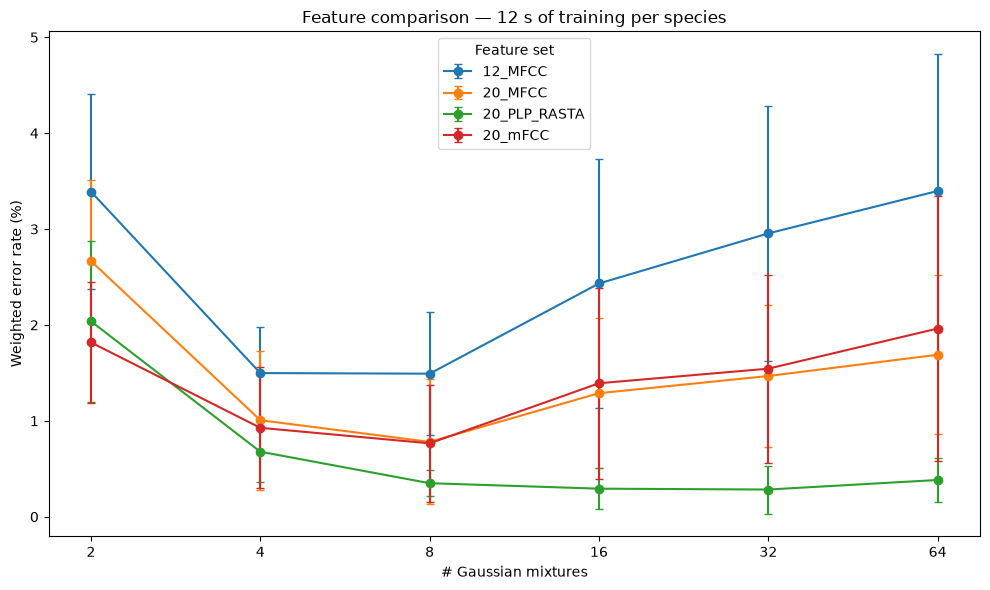

In [17]:
if RUN_FULL_EXPERIMENT:

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    for feature_name in FEATURE_NAMES:

        subset = (
            wer_summary[
                wer_summary["feature"]
                == feature_name
            ]
            .sort_values(
                "n_components"
            )
        )

        ax.errorbar(
            subset["n_components"],
            subset["WER_mean_percent"],
            yerr=subset["WER_std_percent"],
            marker="o",
            capsize=3,
            label=feature_name,
        )

    ax.set_xscale(
        "log",
        base=2,
    )

    ax.set_xticks(
        N_COMPONENTS_GRID
    )

    ax.set_xticklabels(
        [
            str(m)
            for m in N_COMPONENTS_GRID
        ]
    )

    ax.set(
        title="Feature comparison — 12 s of training per species",
        xlabel="# Gaussian mixtures",
        ylabel="Weighted error rate (%)",
    )

    ax.legend(
        title="Feature set"
    )

    plt.tight_layout()
    plt.show()

## 18. Best representation by model order

This makes the Figure-9 comparison explicit rather than leaving the reader to squint at four curves
and discover optometry.

In [18]:
if RUN_FULL_EXPERIMENT:

    best_by_M = (
        wer_summary
        .sort_values(
            [
                "n_components",
                "WER_mean",
            ]
        )
        .groupby(
            "n_components",
            as_index=False,
        )
        .first()
    )

    display(
        best_by_M[
            [
                "n_components",
                "feature",
                "WER_mean_percent",
                "WER_std_percent",
            ]
        ].round(4)
    )

,n_components,feature,WER_mean_percent,WER_std_percent
0,2,20_mFCC,1.8177,0.6304
1,4,20_PLP_RASTA,0.6781,0.3123
2,8,20_PLP_RASTA,0.3496,0.1353
3,16,20_PLP_RASTA,0.2925,0.2165
4,32,20_PLP_RASTA,0.2835,0.2503
5,64,20_PLP_RASTA,0.3831,0.2281


## 19. Per-species diagnostic at M = 64

The paper ultimately selects `M = 64` as its common model order. This table shows which species drive
the feature-level differences at that order.

In [19]:
if RUN_FULL_EXPERIMENT:

    species_M64 = (
        per_species_results[
            per_species_results[
                "n_components"
            ] == 64
        ]
        .groupby(
            [
                "feature",
                "code",
            ],
            as_index=False,
        )["error_rate"]
        .mean()
    )

    species_M64[
        "error_percent"
    ] = (
        species_M64[
            "error_rate"
        ]
        * 100
    )

    display(
        species_M64
        .pivot(
            index="code",
            columns="feature",
            values="error_percent",
        )
        .round(3)
    )

feature,12_MFCC,20_MFCC,20_PLP_RASTA,20_mFCC
code,,,,
f01,0.000,0.000,0.000,0.000
f02,6.293,3.359,0.698,3.790
f03,12.399,5.157,0.268,6.635
f04,0.829,0.637,0.000,0.640
f05,0.197,0.000,0.230,0.033
f06,1.468,0.000,0.000,0.000
f07,1.461,1.978,2.014,1.217
f08,6.778,3.933,0.237,4.897
f10,1.149,0.139,0.000,0.453


## 20. Direct comparison against the paper's qualitative claims

The paper does not provide the raw Figure-9 numerical table, so this notebook does not invent one.

Instead it evaluates the published qualitative claims:

1. Is 20 MFCC better than 12 MFCC?
2. Does reconstructed PLP-RASTA improve on standard MFCC at larger `M`?
3. Does 20 m-FCC obtain the lowest WER?

In [20]:
if RUN_FULL_EXPERIMENT:

    comparison_wide = (
        wer_summary
        .pivot(
            index="n_components",
            columns="feature",
            values="WER_mean_percent",
        )
        .sort_index()
    )

    display(
        comparison_wide.round(4)
    )

    claims = []

    for M in N_COMPONENTS_GRID:

        row = comparison_wide.loc[M]

        claims.append({
            "M": M,
            "20_MFCC_better_than_12_MFCC": (
                row["20_MFCC"]
                < row["12_MFCC"]
            ),
            "PLP_better_than_20_MFCC": (
                row["20_PLP_RASTA"]
                < row["20_MFCC"]
            ),
            "mFCC_best": (
                row["20_mFCC"]
                == row.min()
            ),
        })

    claim_table = pd.DataFrame(
        claims
    )

    display(claim_table)

feature,12_MFCC,20_MFCC,20_PLP_RASTA,20_mFCC
n_components,,,,
2,3.3903,2.6668,2.0382,1.8177
4,1.4981,1.0066,0.6781,0.9272
8,1.4918,0.7803,0.3496,0.7653
16,2.4325,1.2883,0.2925,1.3920
32,2.9547,1.4675,0.2835,1.5440
64,3.3973,1.6893,0.3831,1.9627


,M,20_MFCC_better_than_12_MFCC,PLP_better_than_20_MFCC,mFCC_best
0,2,True,True,True
1,4,True,True,False
2,8,True,True,False
3,16,True,True,False
4,32,True,True,False
5,64,True,True,False


## 21. Save experiment outputs

In [21]:
if RUN_FULL_EXPERIMENT:

    feature_validation.to_csv(
        RESULTS_DIR / "feature_validation.csv",
        index=False,
    )

    wer_results.to_csv(
        RESULTS_DIR / "wer_by_repeat.csv",
        index=False,
    )

    wer_summary.to_csv(
        RESULTS_DIR / "wer_summary.csv",
        index=False,
    )

    per_species_results.to_csv(
        RESULTS_DIR / "per_species_results.csv",
        index=False,
    )

    call_predictions.to_csv(
        RESULTS_DIR / "call_predictions.csv",
        index=False,
    )

    comparison_wide.to_csv(
        RESULTS_DIR / "figure9_comparison_table.csv",
    )

    claim_table.to_csv(
        RESULTS_DIR / "paper_qualitative_claims.csv",
        index=False,
    )

    print("Saved:")
    for path in sorted(
        RESULTS_DIR.iterdir()
    ):
        print(
            " ",
            path.name,
        )

Saved:
  call_feature_sets.joblib
  call_predictions.csv
  feature_validation.csv
  figure9_comparison_table.csv
  paper_qualitative_claims.csv
  per_species_results.csv
  wer_by_repeat.csv
  wer_summary.csv


## 22. Conclusions and limitations

After execution, this notebook should answer the paper's Section-4.2 question:

> **Which cepstral representation gives the lowest macro-averaged call-classification error when GMMs
> are trained with 12 seconds of calls per species?**

### Compatibility note

- Notebook 02 and `calls.csv` remain unchanged.
- `start`/`end` offsets are reconstructed in memory from the same `.mat` segment files used by notebook 02 and verified row-by-row before use.

### Reproduced structure

- Dataset 1 labelled calls only;
- 12 seconds training per species;
- validation on remaining complete calls;
- identical call splits across feature representations;
- `M = 2, 4, 8, 16, 32, 64`;
- ten reproducible random selections;
- one diagonal GMM per species;
- call-level average log-likelihood scoring;
- per-species error followed by macro WER;
- Figure-9-style feature comparison.

### Limitations

- `f09` is unavailable in sufficient quantity.
- The standard MFCC baseline defaults are not fully specified by the article.
- The PLP-RASTA software/settings used by the authors are not reported; this notebook uses an explicit
  standard reconstruction.
- The m-FCC representation inherits notebook 02's reconstruction of the modified filter bank.
- Different feature implementations can produce slightly different frame counts; comparison remains
  call-aligned and split-aligned.

### What comes after this notebook

Only after this feature comparison is complete should the project return to the final detector /
long-recording stages.

The previously created field notebook should therefore be considered a **later-stage prototype**, not
the chronological notebook 05 of the paper replication.

In [25]:
PONDERED_TIME = 4
print("Current time:", PONDERED_TIME)

Current time: 4
